In [ ]:
#| default_exp sonic

# Speed

> Why Kokoro can't simply talk faster, and how to speed up its audio instead: resampling, overlap-add, WSOLA, Sonic.

audio-reader lets listeners go from half speed to three times. Notebook 100's `analyse` takes a `speed`, which divides
every phoneme's duration. That seems like the natural way: the voice itself talks faster. Let's try it.

In [ ]:
#| export
import ctypes
import subprocess
from pathlib import Path

import numpy as np

import text_to_speech
from text_to_speech.voice import SR

In [ ]:
import librosa
import matplotlib.pyplot as plt
from fastcore.test import test_close, test_eq
from IPython.display import Audio, display

from text_to_speech.voice import analyse, decode

## Asking Kokoro

`analyse` rounds each phoneme's duration to whole 25 ms frames, and never fewer than one.

In [ ]:
text = "Speed comes from the voice itself, not from stretching the audio afterwards."
for speed in [1, 2, 3]:
    u = analyse(text, speed=speed)
    audio = decode(u)
    print(f"{speed}x: {len(audio) / SR:.2f}s, {(u.frames == 1).float().mean():.0%} of phonemes at the one-frame floor")
    display(Audio(audio, rate=SR))

1x: 4.83s, 25% of phonemes at the one-frame floor
2x: 2.55s, 86% of phonemes at the one-frame floor
3x: 2.17s, 95% of phonemes at the one-frame floor


3x is barely shorter than 2x: almost every phoneme is already at the floor. And listen to 2x: sounds go missing all
through the sentence. A phoneme that should last one and a half frames gets one, and one 25 ms frame isn't enough for
the decoder to make a /v/ or a /ʧ/. (The appendix measures this with a speech recogniser: Kokoro's own 2x loses about
a word in four.)

So we'll render at 1x and speed the *audio* up. That's also better for a player: the speed can change mid-sentence
without rendering again, and word timings just divide by the speed.

## Playing it faster

The simplest speed-up is to play the samples faster, which here means resampling to fewer samples.

In [ ]:
normal = decode(analyse(text))
chipmunk = librosa.resample(normal, orig_sr=SR * 2, target_sr=SR)
test_eq(len(chipmunk), len(normal) // 2)
Audio(chipmunk, rate=SR)

Half the length, and an octave higher. Pitch and the resonances that make one vowel differ from another (the formants)
all doubled. We need to shorten the audio while keeping every cycle of the voice at its own length.

## Overlap-add

So cut the audio into short overlapping windows and keep only some of them: read windows `speed` times further apart
than they're written, and add them up. Hann windows overlapping by half sum to one, so the level stays the same.

In [ ]:
def ola(x, speed, win=1024):
    "Overlap-add: windows read `speed` times further apart than they are written."
    hop, w = win // 2, np.hanning(win)
    n = int((len(x) - win) / (hop * speed)) + 1
    out = np.zeros(n * hop + win, dtype=np.float32)
    for k in range(n):
        start = round(k * hop * speed)
        out[k * hop : k * hop + win] += x[start : start + win] * w
    return out

In [ ]:
fast = ola(normal, 2)
test_close(len(fast) / len(normal), 0.5, eps=0.01)
Audio(fast, rate=SR)

Right length, right pitch, and rough. Each window is a few cycles of the voice, but nothing makes the cycles of one
window line up with the next, so where they overlap they partly cancel:

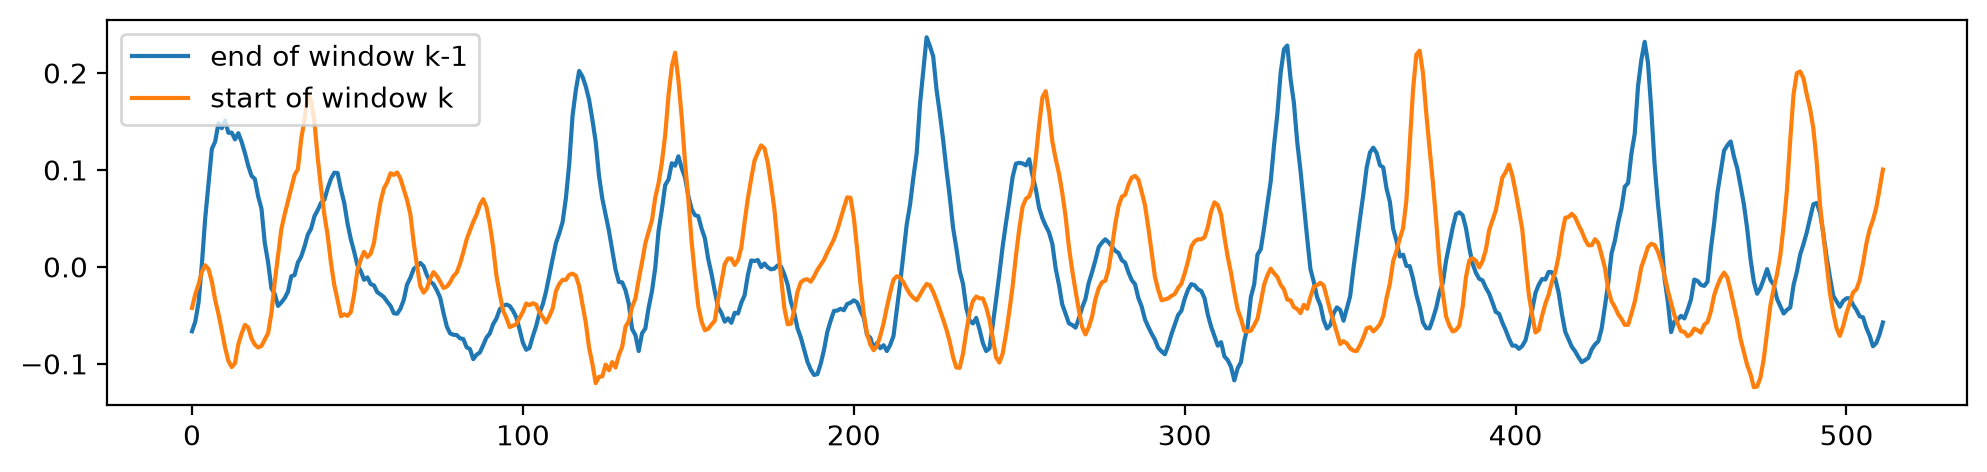

In [ ]:
win, hop = 1024, 512
k = 40  # A window somewhere in a vowel
a, b = round((k - 1) * hop * 2), round(k * hop * 2)
plt.figure(figsize=(12, 2.5))
plt.plot(normal[a + hop : a + win], label="end of window k-1")
plt.plot(normal[b : b + hop], label="start of window k")
plt.legend()
plt.show()

## WSOLA: cut where it lines up

The fix is to move each window a little, within some tolerance of where it should be read from, to wherever the
waveform best matches what would have naturally followed the previous window. That's WSOLA (waveform-similarity
overlap-add). The best match is the peak of a cross-correlation.

In [ ]:
def wsola(x, speed, win=1024, tolerance=256):
    "Overlap-add, with each window moved by up to `tolerance` samples to line up with the last."
    hop, w = win // 2, np.hanning(win)
    n = int((len(x) - win - 2 * tolerance) / (hop * speed))
    out = np.zeros(n * hop + win, dtype=np.float32)
    prev = 0
    for k in range(n):
        follow = x[prev + hop : prev + hop + win]  # What would naturally come next
        lo = max(0, round(k * hop * speed) - tolerance)
        shift = np.argmax(np.correlate(x[lo : lo + 2 * tolerance + win], follow, "valid")) if k else 0
        prev = lo + shift if k else 0
        out[k * hop : k * hop + win] += x[prev : prev + win] * w
    return out

In [ ]:
fast = wsola(normal, 2)
test_close(len(fast) / len(normal), 0.5, eps=0.02)
Audio(fast, rate=SR)

Much smoother. WSOLA lines up the waveform but doesn't know what a voice is. Sonic, written for blind listeners who
run screen readers at three times speed or more, goes one step further: it finds the voice's actual pitch period, and
cuts out whole periods, cross-fading across one. Android's own playback speed control uses a port of it. It's one
Apache-licensed C file, vendored in `vendor/sonic`. (The appendix compares six speed-ups by ear and by speech
recogniser, and Sonic wins.)

## Sonic

We compile it the first time it's needed and call it through `ctypes`.

In [ ]:
#| export
SONIC = Path(text_to_speech.__file__).parents[1] / "vendor" / "sonic"


def load_sonic():
    "Compile vendor/sonic/sonic.c into a shared library if it isn't there yet, and load it."
    lib = SONIC / "libsonic.dylib"
    if not lib.exists():
        subprocess.run(["cc", "-O2", "-shared", "-fPIC", SONIC / "sonic.c", "-o", lib], check=True)
    lib = ctypes.CDLL(str(lib))
    p, i, f, floats = ctypes.c_void_p, ctypes.c_int, ctypes.c_float, ctypes.POINTER(ctypes.c_float)
    lib.sonicCreateStream.argtypes, lib.sonicCreateStream.restype = [i, i], p
    lib.sonicDestroyStream.argtypes = [p]
    lib.sonicSetSpeed.argtypes = [p, f]
    lib.sonicWriteFloatToStream.argtypes = [p, floats, i]
    lib.sonicReadFloatFromStream.argtypes = [p, floats, i]
    lib.sonicFlushStream.argtypes = [p]
    lib.sonicChangeFloatSpeed.argtypes = [floats, i, f, f, f, f, i, i, i]
    return lib


libsonic = load_sonic()


def _floats(x):
    return x.ctypes.data_as(ctypes.POINTER(ctypes.c_float))


def sonic(x, speed):
    "Speed up mono `x` by `speed`, keeping its pitch."
    buf = np.zeros(len(x) + SR, dtype=np.float32)
    buf[: len(x)] = x
    n = libsonic.sonicChangeFloatSpeed(_floats(buf), len(x), speed, 1, 1, 1, 0, SR, 1)  # pitch, rate, volume = 1
    return buf[:n]

In [ ]:
for speed in [1.5, 2, 3]:
    fast = sonic(normal, speed)
    test_close(len(fast) / len(normal), 1 / speed, eps=0.01)
    print(f"{speed}x")
    display(Audio(fast, rate=SR))

1.5x
2x
3x


## A stream

A player can't hand Sonic a whole sentence and wait: it feeds audio in as it goes, reads sped-up audio out, and
changes speed whenever the listener asks. Sonic's streaming interface does exactly that.

In [ ]:
#| export
class Sonic:
    "Sonic's streaming interface: write 1x audio in, read sped-up audio out, change the speed at any time."

    def __init__(self, speed=1.0):
        self.lib = libsonic  # Held here so `__del__` still has it while Python shuts down
        self.stream = self.lib.sonicCreateStream(SR, 1)
        self.set_speed(speed)

    def set_speed(self, speed):
        self.lib.sonicSetSpeed(self.stream, speed)

    def write(self, x):
        self.lib.sonicWriteFloatToStream(self.stream, _floats(x), len(x))

    def read(self, out):
        "Fill as much of `out` as Sonic has ready. Returns how many samples that was."
        return self.lib.sonicReadFloatFromStream(self.stream, _floats(out), len(out))

    def flush(self):
        "Process whatever has been written, without waiting for more."
        self.lib.sonicFlushStream(self.stream)

    def __del__(self):
        self.lib.sonicDestroyStream(self.stream)

A second in at 2x is half a second out; then at 3x, a third:

In [ ]:
s, out = Sonic(2), np.zeros(SR, np.float32)
x = normal[:SR].astype(np.float32)
s.write(x)
s.flush()
test_close(s.read(out) / SR, 0.5, eps=0.01)
s.set_speed(3)
s.write(x)
s.flush()
test_close(s.read(out) / SR, 1 / 3, eps=0.01)

## Summary

- Kokoro's own `speed` runs out of 25 ms frames: sounds drop from about 1.5x, and it can't get much past 2x.
- Resampling speeds up the pitch too. Overlap-add keeps the pitch but is rough; lining up the windows (WSOLA) fixes
  most of that; Sonic, cutting whole pitch periods, is the best of all.
- `sonic` speeds up a clip. `Sonic` is a stream whose speed can change at any moment, which is what the player in
  notebook 102 needs.